# 08 · Flow matching and rectified flow: the modern, simpler formulation

Diffusion models learn a *score* and integrate a reverse-time SDE (or its probability-flow ODE).
**Flow matching** skips the SDE altogether: pick a simple path from data to noise, and regress a
neural *velocity field* whose ODE carries noise back to data. This is the formulation behind
Stable Diffusion 3, Flux and many recent video, audio and robot-policy models. We derive it from
scratch, check every step against an exact ground truth, and then show that it is the same
object as a diffusion model, seen in different coordinates.

**You will learn:**
- why regressing on the per-sample velocity $\varepsilon - x_0$ learns the *marginal* velocity
  $v(x,t)=\mathbb E[\varepsilon - x_0\mid x_t=x]$ (a posterior mean again, like Tweedie), and why that velocity transports noise to data;
- the closed-form velocity field of a Gaussian mixture, which we use as ground truth;
- how to train a flow-matching model in ~20 lines and sample it with Euler / Heun, and how it compares to DDPM/DDIM at equal cost;
- why the learned trajectories are curved, and how to measure straightness;
- the exact dictionary between flow matching and diffusion ($\hat x_0$, $\hat\varepsilon$, $v$, SNR, loss weighting; DDIM *is* Euler);
- two ways to straighten the flow for 1–2-step sampling: **reflow** (rectified flow) and **mini-batch optimal-transport** couplings;
- the practical knobs used in large models: timestep distributions, step counts, guidance on velocities.

**Prerequisites:** 01 (forward process), 02 (DDPM), 03 (score matching, Tweedie), 04 (DDIM / probability-flow ODE); 06 (guidance) for the last section.

**Runtime:** about 5–10 min on a laptop CPU (five small MLPs of 0.5–1.5 min each, plus sampling); about 2–4 min on a GPU (tiny MLPs, so a GPU helps less than usual).

In [1]:
import copy
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10,
                     "axes.labelsize": 9, "legend.fontsize": 8})

# --- budget knobs (FAST mode only checks that every code path runs) ---
STEPS = 300 if FAST else 5000           # optimisation steps for each model trained from scratch
BATCH, LR = 256, 1e-3
N_TRAIN = 5_000 if FAST else 50_000     # size of the training set
N_EVAL = 500 if FAST else 2000          # samples used for every MMD estimate
N_PLOT = 600                            # points drawn per scatter panel (keeps the notebook small)
NFES = [1, 2, 8] if FAST else [1, 2, 4, 8, 16, 32, 64]   # numbers of function evaluations to sweep

# one colour per method, used in every figure
COL = dict(data="0.75", exact="k", fm="tab:blue", ddpm="tab:orange", reflow="tab:green", ot="tab:purple")

Using device: cpu


**Conventions for this notebook (they differ from notebooks 01–06!).** Time is continuous,
$t\in[0,1]$, with **data at $t=0$ and noise at $t=1$** (the rectified-flow / SD3 convention):

$$x_t = (1-t)\,x_0 + t\,\varepsilon,\qquad x_0\sim p_{\rm data},\ \ \varepsilon\sim\mathcal N(0,I).$$

We sample by integrating an ODE *backwards*, from $t=1$ to $t=0$. (Lipman et al. 2023 and several
codebases use the opposite direction, noise at $t=0$ and data at $t=1$, which flips the sign of the
velocity: always check the convention when reading papers or code.) The networks are
`dm.MLPDenoiser`s, whose sinusoidal time embedding was designed for the integer steps
$0,\dots,999$ of earlier notebooks, so **we feed them $1000\,t$**. (Gotcha: feeding
$t\in[0,1]$ directly "works" but the embedding then varies so slowly that the network
struggles to tell noise levels apart.)

Our data is the 8-component 2-D Gaussian mixture `dm.default_gmm()`, chosen because every
quantity in this notebook (densities, posterior means, velocities) has a closed form for it.

In [2]:
def time_input(t):
    """Map flow time t in [0, 1] to the input range the MLP's sinusoidal embedding expects."""
    return 1000.0 * t


gmm = dm.default_gmm()
g = torch.Generator().manual_seed(0)
data = gmm.sample(N_TRAIN, generator=g)          # fixed training set (CPU)
test = gmm.sample(N_EVAL, generator=g)           # held-out samples for evaluation
data_dev = data.to(device)

# MMD between two independent sets of true samples = the best score any sampler can hope for
MMD_FLOOR = dm.mmd_rbf(gmm.sample(N_EVAL, generator=g), test)
print(f"training set {tuple(data.shape)}, mean {data.mean(0).numpy().round(2)}, std {data.std(0).numpy().round(2)}")
print(f"MMD between two independent sets of {N_EVAL} true samples (noise floor): {MMD_FLOOR:.4f}")

training set (50000, 2), mean [-0.   -0.01], std [1.03 1.03]
MMD between two independent sets of 2000 true samples (noise floor): 0.0039


## 1 · From scores to velocities

**Intuition.** A diffusion model learns the score $\nabla\log p_t$ and then needs a
(stochastic or probability-flow) differential equation built from it to generate.
Flow matching asks a more direct question: *which velocity field $v(x,t)$ moves a cloud of
Gaussian noise into the data distribution?* If we had it, sampling would just be
"draw $x_1\sim\mathcal N(0,I)$ and integrate $\dot x = v(x,t)$ from $t=1$ to $t=0$".

**The continuity equation.** A velocity field $v$ moves a density $p_t$ around without
creating or destroying mass, which is expressed by

$$\partial_t p_t(x) + \nabla\cdot\big(p_t(x)\,v(x,t)\big) = 0 .$$

So we want *some* $v$ that satisfies this for the path $p_t$ = law of $x_t=(1-t)x_0+t\varepsilon$.

**Each pair moves in a straight line.** For a fixed pair $(x_0,\varepsilon)$ the point
$x_t$ travels at constant velocity $\dot x_t = \varepsilon - x_0$. Many pairs pass through the
same location $x$ at time $t$, with different velocities; the natural guess is their average:

$$v(x,t) \;=\; \mathbb E\left[\varepsilon - x_0 \,\middle|\, x_t = x\right].$$

**Claim: this $v$ satisfies the continuity equation.** Take any smooth test function $\varphi$ with compact support:

$$\frac{d}{dt}\mathbb E[\varphi(x_t)]
= \mathbb E\big[\nabla\varphi(x_t)^\top(\varepsilon - x_0)\big]
\overset{\text{tower}}{=} \mathbb E\big[\nabla\varphi(x_t)^\top\,\mathbb E[\varepsilon - x_0\mid x_t]\big]
= \int \nabla\varphi(x)^\top v(x,t)\,p_t(x)\,dx
= -\int \varphi(x)\,\nabla\cdot\big(p_t v\big)(x)\,dx ,$$

(the last step integrates by parts). The left side is $\int\varphi\,\partial_t p_t\,dx$, and since this holds for every $\varphi$,
$\partial_t p_t = -\nabla\cdot(p_t v)$. Under mild regularity (a Lipschitz $v$), the ODE
$\dot x = v(x,t)$ started from $p_1=\mathcal N(0,I)$ therefore has marginal $p_t$ at every time,
and in particular produces $p_0 = p_{\rm data}$ at $t=0$. Note that the ODE paths are *not* the
straight lines: each particle follows the *averaged* velocity (Section 4).

**The training objective.** We cannot regress on $v$ directly (it is an intractable
conditional expectation), but we *can* regress on the per-sample velocity:

$$\mathcal L_{\rm FM}(\theta) = \mathbb E_{t,x_t}\|v_\theta(x_t,t) - v(x_t,t)\|^2 ,\qquad
\mathcal L_{\rm CFM}(\theta) = \mathbb E_{t,x_0,\varepsilon}\|v_\theta(x_t,t) - (\varepsilon - x_0)\|^2 .$$

Write $u=\varepsilon-x_0$ and expand the square. The only term that involves both $\theta$ and $u$ is

$$\mathbb E\big[v_\theta(x_t,t)^\top u\big] = \mathbb E\big[v_\theta(x_t,t)^\top\,\mathbb E[u\mid x_t]\big] = \mathbb E\big[v_\theta(x_t,t)^\top v(x_t,t)\big],$$

again by the tower property. Hence

$$\mathcal L_{\rm CFM}(\theta) = \mathcal L_{\rm FM}(\theta) + \underbrace{\mathbb E\|u\|^2 - \mathbb E\|v\|^2}_{C\;=\;\mathbb E\,\mathrm{tr}\,\mathrm{Cov}[u\mid x_t]\ \ (\text{no }\theta)} ,
\qquad\Rightarrow\qquad \nabla_\theta\mathcal L_{\rm CFM} = \nabla_\theta\mathcal L_{\rm FM}.$$

Two consequences: (i) the tractable "conditional" loss has the same minimiser, the
posterior mean $v$, exactly as in denoising score matching (notebook 03, Vincent 2011);
(ii) the loss **cannot reach zero**: it plateaus at $C$, the average posterior variance of
$\varepsilon - x_0$. A plateauing flow-matching loss is not a bug.

**A Bayesian reading.** $x_t$ is a noisy observation of the latent $x_0$ with likelihood
$\mathcal N(x_t;(1-t)x_0,\,t^2 I)$. Since $\varepsilon = (x_t-(1-t)x_0)/t$,

$$v(x,t) = \mathbb E[\varepsilon\mid x_t=x] - \mathbb E[x_0\mid x_t=x] = \frac{x-(1-t)\hat x_0}{t} - \hat x_0 = \frac{x - \hat x_0(x,t)}{t},
\qquad \hat x_0(x,t) := \mathbb E[x_0\mid x_t = x].$$

The velocity is "the vector from the posterior mean to where you are, divided by the
remaining time". Integrating backwards in time ($dt<0$) moves each particle towards the
current best guess of the clean data, while that guess sharpens as the noise shrinks.

## 2 · The exact velocity field of a Gaussian mixture

For $p_{\rm data}=\sum_k \pi_k\,\mathcal N(\mu_k,\Sigma_k)$ everything is Gaussian once we
condition on the component $k$. Given $k$, $(x_0, x_t)$ is jointly Gaussian with

$$\mathbb E[x_t\mid k] = (1-t)\mu_k,\qquad S_k(t) := \mathrm{Cov}[x_t\mid k] = (1-t)^2\Sigma_k + t^2 I,\qquad
\mathrm{Cov}[x_0,x_t\mid k] = (1-t)\Sigma_k .$$

So $p_t$ is again a GMM (means $(1-t)\mu_k$, covariances $S_k$), and standard Gaussian conditioning gives

$$\mathbb E[x_0\mid x_t,k] = \mu_k + (1-t)\,\Sigma_k S_k^{-1}\big(x_t-(1-t)\mu_k\big),\qquad
r_k(x_t) = \frac{\pi_k\,\mathcal N(x_t;(1-t)\mu_k,S_k)}{\sum_j \pi_j\,\mathcal N(x_t;(1-t)\mu_j,S_j)},$$

$$\hat x_0(x_t) = \sum_k r_k(x_t)\,\mathbb E[x_0\mid x_t,k],\qquad v(x_t,t) = \frac{x_t-\hat x_0(x_t)}{t}.$$

**An independent route via the score.** Because $x_t\mid x_0\sim\mathcal N((1-t)x_0,t^2I)$,
Tweedie's formula (notebook 03) gives $\mathbb E[\varepsilon\mid x_t] = -t\,\nabla\log p_t(x_t)$ and
$\hat x_0 = (x_t + t^2\nabla\log p_t)/(1-t)$; subtracting,

$$v(x,t) = -\frac{x + t\,\nabla\log p_t(x)}{1-t}.$$

The first form is singular at $t=0$, the second at $t=1$; we implement the first and use
`dm.GaussianMixture.score` to check it against the second.

In [3]:
def flow_marginal(gmm, t):
    """The marginal p_t of x_t = (1-t) x0 + t eps when x0 ~ gmm: again a GMM."""
    I = torch.eye(gmm.d, dtype=torch.float64)
    return dm.GaussianMixture(gmm.weights, (1 - t) * gmm.means, (1 - t) ** 2 * gmm.covs + t ** 2 * I)


def exact_velocity(gmm, x, t, t_min=1e-4):
    """Exact marginal velocity v(x,t) = E[eps - x0 | x_t = x] and posterior mean E[x0 | x_t = x].

    x: (n, d) on any device; t: float or (n,) tensor. The maths runs in float64 on the CPU
    (Apple MPS has no float64); results come back as float32 on x's device.
    """
    dev = x.device
    x = x.detach().cpu().double()
    n, d = x.shape
    t = torch.as_tensor(t, dtype=torch.float64).cpu().expand(n).clamp(t_min, 1.0)  # (n,)
    a = (1 - t)[:, None, None]                                             # broadcasts over (n, K, d)
    S = a[..., None] ** 2 * gmm.covs + t[:, None, None, None] ** 2 * torch.eye(d, dtype=torch.float64)
    L = torch.linalg.cholesky(S)                                           # (n, K, d, d)
    diff = x[:, None, :] - a * gmm.means                                   # x - (1-t) mu_k
    sol = torch.cholesky_solve(diff[..., None], L)[..., 0]                 # S_k^{-1} (x - (1-t) mu_k)
    log_lik = -0.5 * (diff * sol).sum(-1) - torch.log(torch.diagonal(L, dim1=-2, dim2=-1)).sum(-1)
    resp = torch.softmax(torch.log(gmm.weights) + log_lik, dim=1)          # r_k(x): which component?
    x0_k = gmm.means + a * torch.einsum("kij,nkj->nki", gmm.covs, sol)    # E[x0 | x_t, k]
    x0_hat = (resp[..., None] * x0_k).sum(1)                               # E[x0 | x_t]
    v = (x - x0_hat) / t[:, None]
    return v.float().to(dev), x0_hat.float().to(dev)


# CHECK 1: posterior-mean formula vs. score formula (dmtools' exact GMM score of p_t)
xq = 1.5 * torch.randn(1000, 2, generator=torch.Generator().manual_seed(1))
for t in [0.1, 0.5, 0.9]:
    v, _ = exact_velocity(gmm, xq, t)
    v_score = -(xq + t * flow_marginal(gmm, t).score(xq)) / (1 - t)
    err = (v - v_score).abs().max().item()
    print(f"t = {t:.1f}: max |v_posterior - v_score| = {err:.1e}   (max |v| = {v.abs().max():.1f})")
    assert err < 1e-3

t = 0.1: max |v_posterior - v_score| = 1.9e-06   (max |v| = 11.4)
t = 0.5: max |v_posterior - v_score| = 9.5e-07   (max |v| = 8.0)
t = 0.9: max |v_posterior - v_score| = 4.8e-06   (max |v| = 5.8)


A second, fully independent check: estimate the posterior mean by **self-normalised importance
sampling** — draw prior samples $x_0^{(i)}\sim p_{\rm data}$ and weight each by the likelihood
$\mathcal N(x;(1-t)x_0^{(i)},t^2I)$, just like a particle filter's measurement update.

In [4]:
def velocity_monte_carlo(x, t, x0_samples):
    """Importance-sampling estimate of E[eps - x0 | x_t = x] using prior samples of x0."""
    x, x0s = x.double(), x0_samples.double()
    log_w = -((x[:, None, :] - (1 - t) * x0s[None]) ** 2).sum(-1) / (2 * t ** 2)
    w = torch.softmax(log_w, dim=1)                       # normalised posterior weights
    x0_hat = w @ x0s
    ess = 1.0 / (w ** 2).sum(1)                           # effective sample size
    return ((x - x0_hat) / t).float(), ess


x0_prior = gmm.sample(20_000 if FAST else 200_000, generator=torch.Generator().manual_seed(2))
queries = torch.tensor([[0.5, 0.5], [-1.0, 0.2], [0.0, -1.5], [1.8, -0.4]])
for t in [0.3, 0.6, 0.9]:
    v_mc, ess = velocity_monte_carlo(queries, t, x0_prior)
    v_ex, _ = exact_velocity(gmm, queries, t)
    err = (v_mc - v_ex).norm(dim=1).max().item()
    print(f"t = {t:.1f}: max ||v_MC - v_exact|| = {err:.3f}  (min ESS {ess.min():.0f}, mean ||v|| {v_ex.norm(dim=1).mean():.2f})")
    assert err < 0.15

t = 0.3: max ||v_MC - v_exact|| = 0.025  (min ESS 20534, mean ||v|| 0.96)
t = 0.6: max ||v_MC - v_exact|| = 0.011  (min ESS 66124, mean ||v|| 0.52)


t = 0.9: max ||v_MC - v_exact|| = 0.003  (min ESS 189764, mean ||v|| 1.23)

Both checks pass: the closed form agrees with the score route to float precision and with
the brute-force Bayesian posterior up to Monte-Carlo error.

**Numerical check of the CFM ⇔ FM identity.** For *any* function $f(x,t)$ the identity above says
$\mathcal L_{\rm CFM}(f) - \mathcal L_{\rm CFM}(v) = \mathcal L_{\rm FM}(f)$. With the exact $v$
we can verify this by Monte Carlo for a few deliberately wrong $f$, and compute the loss floor $C$.

In [5]:
N_MC = 40_000 if FAST else 400_000
g = torch.Generator().manual_seed(3)
x0_mc, eps_mc, t_mc = gmm.sample(N_MC, generator=g), torch.randn(N_MC, 2, generator=g), torch.rand(N_MC, generator=g)
xt_mc = (1 - t_mc[:, None]) * x0_mc + t_mc[:, None] * eps_mc
u_mc = eps_mc - x0_mc                                   # conditional (per-pair) velocity
v_mc, _ = exact_velocity(gmm, xt_mc, t_mc)              # marginal velocity, one t per sample

sq = lambda a, b: ((a - b) ** 2).sum(1)
CFM_FLOOR = sq(v_mc, u_mc).mean().item()                # the irreducible part C
print(f"loss floor C = E||v - u||^2 = {CFM_FLOOR:.3f} ± {sq(v_mc, u_mc).std().item() / math.sqrt(N_MC):.3f}\n")
print(f"{'candidate f':>14} | {'L_CFM(f) - L_CFM(v)':>20} | {'L_FM(f)':>8}")
for name, f in {"0": torch.zeros_like(xt_mc), "-x_t": -xt_mc, "0.5 v": 0.5 * v_mc,
                "v + 0.3": v_mc + 0.3}.items():
    lhs = sq(f, u_mc).mean().item() - CFM_FLOOR
    rhs = sq(f, v_mc).mean().item()
    print(f"{name:>14} | {lhs:20.3f} | {rhs:8.3f}")

loss floor C = E||v - u||^2 = 2.801 ± 0.005

   candidate f |  L_CFM(f) - L_CFM(v) |  L_FM(f)
             0 |                1.323 |    1.329
          -x_t |                2.575 |    2.577
         0.5 v |                0.329 |    0.332
       v + 0.3 |                0.183 |    0.180


The two columns agree for every candidate, as the derivation says. The floor $C$ is large
(it is an average posterior variance), which is why flow-matching training losses look
"stuck" well above zero.

Now let's look at the field itself. Arrows show $-v\,\Delta t$ with $\Delta t=0.15$, i.e.
where a particle moves in the next 0.15 units of *backward* time; the background is $\log p_t$.

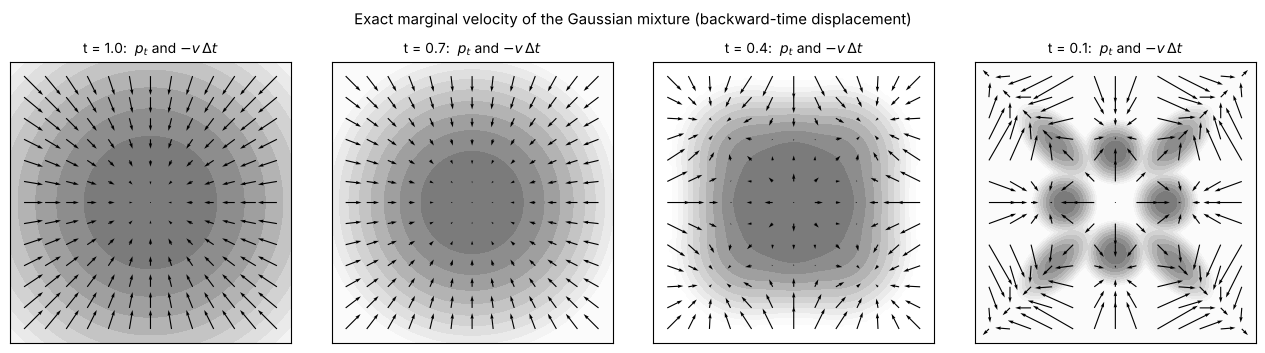

In [6]:
def plot_density(ax, gm, lim=3.0, n=120, cmap="Greys"):
    """Filled contours of log p for a GaussianMixture (background for vector fields)."""
    g1 = torch.linspace(-lim, lim, n)
    X, Y = torch.meshgrid(g1, g1, indexing="xy")
    lp = gm.log_prob(torch.stack([X.flatten(), Y.flatten()], 1)).reshape(n, n)
    levels = np.linspace(lp.max().item() - 10, lp.max().item(), 11)
    # opaque fills (alpha would draw seams between levels); vmax > max keeps the darkest level mid-grey
    ax.contourf(X.numpy(), Y.numpy(), lp.clamp(min=levels[0]).numpy(), levels=levels, cmap=cmap,
                vmin=levels[0], vmax=levels[-1] + 0.6 * (levels[-1] - levels[0]))
    ax.set_aspect("equal")


def plot_field(ax, vfn, t, lim=3.0, n=13, dt=0.15, color="k", width=0.004, **kw):
    """Quiver of the displacement -v * dt (backward-time motion) on a grid."""
    g1 = torch.linspace(-lim * 0.9, lim * 0.9, n)
    X, Y = torch.meshgrid(g1, g1, indexing="xy")
    pts = torch.stack([X.flatten(), Y.flatten()], 1)
    with torch.no_grad():
        d = -dt * vfn(pts.to(device), t).cpu()
    ax.quiver(pts[:, 0], pts[:, 1], d[:, 0], d[:, 1], angles="xy", scale_units="xy", scale=1,
              color=color, width=width, **kw)


def exact_vfn(gm):
    """The exact velocity of a GMM as a function v(x, t) with scalar t."""
    return lambda x, t: exact_velocity(gm, x, t)[0]


fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, t in zip(axes, [1.0, 0.7, 0.4, 0.1]):
    plot_density(ax, flow_marginal(gmm, t))
    plot_field(ax, exact_vfn(gmm), t)
    ax.set_title(f"t = {t}:  $p_t$ and $-v\\,\\Delta t$")
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Exact marginal velocity of the Gaussian mixture (backward-time displacement)", y=1.02)
plt.tight_layout()
plt.show()

At $t=1$ the field is radial: there $\hat x_0 = \mathbb E[x_0]$ for every $x$, so
$v = x - \mathbb E[x_0]$ and every particle first heads to the data mean. As $t$ decreases,
the posterior commits to components, the field splits into basins, and near $t=0$ it points
sharply onto the (thin, anisotropic) mixture components.

## 3 · Training a flow-matching model

The training loop is short enough to write out in full. Per step: draw a batch of pairs
$(x_0,\varepsilon)$, a time $t\sim U(0,1)$ per example, form $x_t$, and regress the network
output onto $\varepsilon - x_0$. Practical details:

* `t[:, None]` broadcasts the per-example time over the data dimensions (for images: `t[:, None, None, None]`);
  forgetting it is the most common shape bug.
* The pair sampler is a function argument, so the *same* loop will later train reflow (fixed
  pairs) and OT-CFM (re-paired batches). An optional label `y` enables classifier-free guidance (Section 8).
* We use the same optimiser, learning rate, warm-up, gradient clipping and **EMA** as
  `dm.train_diffusion` (notebook 05), and sample with the EMA weights.

In [7]:
def make_mlp(n_classes=None):
    """The same small residual MLP for every model in this notebook."""
    return dm.MLPDenoiser(data_dim=2, hidden=128, n_blocks=3, emb_dim=64, n_classes=n_classes).to(device)


def independent_pairs(x_data):
    """Vanilla flow matching: x0 and eps drawn independently."""
    def sample(bs):
        x0 = x_data[torch.randint(0, len(x_data), (bs,), device=x_data.device)]
        return x0, torch.randn_like(x0)
    return sample


def train_flow(model, sample_pairs, steps=STEPS, bs=BATCH, lr=LR, warmup=100, ema_decay=0.999,
               p_uncond=0.0, t_sampler=None, log_every=0):
    """Conditional flow matching. Returns (EMA model, per-step losses)."""
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warmup))
    ema, losses = dm.EMA(model, ema_decay), []
    model.train()
    for step in range(steps):
        x0, eps, *y = sample_pairs(bs)                   # optional third element: class labels
        y = y[0] if y else None
        if y is not None and p_uncond > 0:               # CFG: sometimes replace the label by "null"
            y = torch.where(torch.rand(bs, device=y.device) < p_uncond, torch.full_like(y, model.n_classes), y)
        t = torch.rand(bs, device=x0.device) if t_sampler is None else t_sampler(bs, x0.device)
        xt = (1 - t[:, None]) * x0 + t[:, None] * eps    # point on the straight line between the pair
        loss = F.mse_loss(model(xt, time_input(t), y), eps - x0)   # regress onto the pair's velocity
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); ema.update(model)
        losses.append(loss.item())
        if log_every and (step + 1) % log_every == 0:
            print(f"  step {step + 1:5d} | loss {np.mean(losses[-log_every:]):.4f}")
    model.eval()
    return ema.model, np.array(losses)


dm.seed_everything(0)
t0 = time.time()
fm_model, fm_losses = train_flow(make_mlp(), independent_pairs(data_dev), log_every=STEPS // 4)
n_params = sum(p.numel() for p in fm_model.parameters())   # (dm.count_params skips the frozen EMA copy)
print(f"flow-matching MLP ({n_params / 1e3:.0f}k params) trained in {time.time() - t0:.0f}s")

  step  1250 | loss 1.5097


  step  2500 | loss 1.4399


  step  3750 | loss 1.4261


  step  5000 | loss 1.4197
flow-matching MLP (126k params) trained in 51s


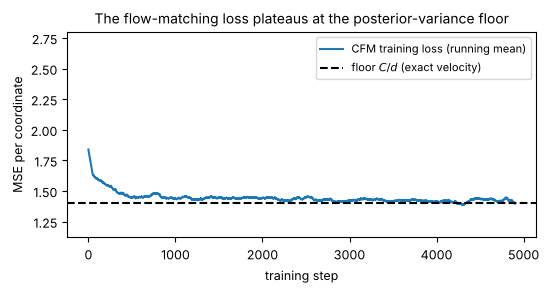

final loss (last 500 steps): 1.426   floor C/d: 1.401


In [8]:
def smooth(x, w=100):
    """Running mean, for readable loss curves."""
    w = min(w, len(x))
    return np.convolve(x, np.ones(w) / w, mode="valid")


fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(smooth(fm_losses), color=COL["fm"], label="CFM training loss (running mean)")
# F.mse_loss averages over the 2 coordinates, so compare with C / d
ax.axhline(CFM_FLOOR / 2, color=COL["exact"], ls="--", label="floor $C/d$ (exact velocity)")
ax.set_ylim(CFM_FLOOR / 2 * 0.8, CFM_FLOOR / 2 * 2.0)
ax.set_xlabel("training step"); ax.set_ylabel("MSE per coordinate"); ax.legend()
ax.set_title("The flow-matching loss plateaus at the posterior-variance floor")
plt.tight_layout()
plt.show()
print(f"final loss (last 500 steps): {fm_losses[-500:].mean():.3f}   floor C/d: {CFM_FLOOR / 2:.3f}")

The loss approaches the floor computed from the exact velocity, but never reaches zero:
the remaining gap is the model's FM error $\mathcal L_{\rm FM}$, which is invisible in the raw loss
unless you know $C$ — a good reason to always keep a toy problem with ground truth around.

### Sampling: Euler and Heun from $t=1$ to $t=0$

On a grid $1=t_0>t_1>\dots>t_N=0$ with step $h_i=t_{i+1}-t_i<0$:

* **Euler** (1 network evaluation, NFE, per step): $x_{i+1} = x_i + h_i\,v_\theta(x_i,t_i)$.
* **Heun** (2 NFE per step): predict $\tilde x = x_i + h_i v_\theta(x_i,t_i)$, then correct with the
  average slope, $x_{i+1} = x_i + \tfrac{h_i}{2}\big(v_\theta(x_i,t_i) + v_\theta(\tilde x,t_{i+1})\big)$.
  Second-order accurate, so it wins when the trajectory is smooth and you can afford few steps.

Cost is measured in NFE, so we compare samplers at equal NFE.

In [9]:
@torch.no_grad()
def ode_sample(vfn, x1, n_steps=None, method="euler", ts=None, return_path=False):
    """Integrate dx/dt = vfn(x, t) from t=1 (noise) to t=0 (data).

    Uses a uniform grid with n_steps steps unless an explicit decreasing grid `ts` is given.
    NFE = n_steps for Euler, 2 * n_steps for Heun. return_path=True also returns the states (S+1, N, d).
    """
    ts = torch.linspace(1.0, 0.0, n_steps + 1).tolist() if ts is None else [float(s) for s in ts]
    x, path = x1.clone(), [x1.cpu()]
    for t, s in zip(ts[:-1], ts[1:]):
        h = s - t                                        # negative: we integrate backwards in time
        v = vfn(x, t)
        if method == "euler":
            x = x + h * v
        elif method == "heun":
            x_pred = x + h * v
            x = x + 0.5 * h * (v + vfn(x_pred, s))       # trapezoidal correction
        else:
            raise ValueError(method)
        if return_path:
            path.append(x.cpu())
    return (x, torch.stack(path)) if return_path else x


def model_vfn(model, y=None):
    """Wrap a network as v(x, t) with scalar flow time t in [0, 1]."""
    return lambda x, t: model(x, torch.full((x.shape[0],), time_input(t), device=x.device), y)


def mmd(x):
    """Sample quality vs held-out data. (.cpu(): mmd_rbf works in float64, which MPS lacks.)"""
    return dm.mmd_rbf(x.detach().cpu(), test)

**A fair diffusion baseline.** Same network, same data, same optimiser and number of steps, but
trained with the DDPM $\varepsilon$-prediction loss on the linear VP schedule (notebook 02) via
`dm.train_diffusion`. Its deterministic sampler is DDIM (notebook 04) with `n_steps` = NFE.
(`amp=False` keeps both runs in float32 on any device.)

In [10]:
schedule = dm.NoiseSchedule(1000, "linear", device=device)
dm.seed_everything(0)
t0 = time.time()
ddpm_out = dm.train_diffusion(make_mlp(), data, schedule, steps=STEPS, batch_size=BATCH, lr=LR,
                              ema_decay=0.999, amp=False, progress=False, log_every=STEPS // 4, device=device)
ddpm_model = ddpm_out["ema"].model
print(f"DDPM MLP trained in {time.time() - t0:.0f}s")

step   1250 | loss 0.2683


step   2500 | loss 0.2311


step   3750 | loss 0.2285


step   5000 | loss 0.2282
DDPM MLP trained in 56s


In [11]:
x1_eval = torch.randn(N_EVAL, 2, generator=torch.Generator().manual_seed(4)).to(device)
quality = {k: [] for k in ["fm_euler", "fm_heun", "exact_euler", "ddim"]}
for nfe in NFES:
    quality["fm_euler"].append(mmd(ode_sample(model_vfn(fm_model), x1_eval, nfe)))
    quality["fm_heun"].append(mmd(ode_sample(model_vfn(fm_model), x1_eval, nfe // 2, "heun")) if nfe >= 2 else np.nan)
    quality["exact_euler"].append(mmd(ode_sample(exact_vfn(gmm), x1_eval, nfe)))
    # dm.ddim_sample's grid always ends with an evaluation at t=0, so it needs >= 2 NFE to move at all
    quality["ddim"].append(mmd(dm.ddim_sample(ddpm_model, schedule, x1_eval.shape, n_steps=nfe, x_T=x1_eval))
                           if nfe >= 2 else np.nan)
print(f"{'NFE':>4} | " + " | ".join(f"{k:>11}" for k in quality))
for i, nfe in enumerate(NFES):
    print(f"{nfe:4d} | " + " | ".join(f"{quality[k][i]:11.4f}" for k in quality))

 NFE |    fm_euler |     fm_heun | exact_euler |        ddim
   1 |      3.9922 |         nan |      4.7417 |         nan
   2 |      0.4396 |      0.6816 |      0.4664 |      0.3461
   4 |      0.0496 |      0.0976 |      0.0584 |      0.4861
   8 |      0.0187 |      0.0106 |      0.0208 |      0.0654
  16 |      0.0086 |      0.0064 |      0.0090 |      0.0175
  32 |      0.0063 |      0.0059 |      0.0058 |      0.0090
  64 |      0.0057 |      0.0059 |      0.0050 |      0.0070


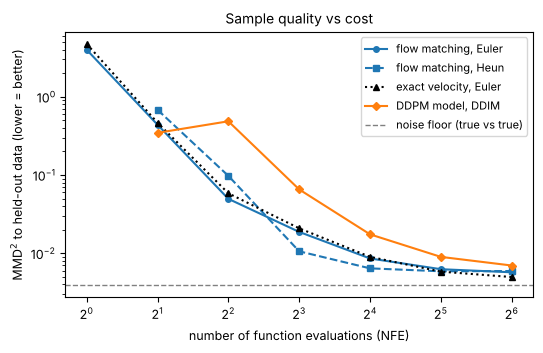

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
style = {"fm_euler": ("flow matching, Euler", COL["fm"], "o-"), "fm_heun": ("flow matching, Heun", COL["fm"], "s--"),
         "exact_euler": ("exact velocity, Euler", COL["exact"], "^:"), "ddim": ("DDPM model, DDIM", COL["ddpm"], "D-")}
for k, (lab, c, m) in style.items():
    ax.plot(NFES, quality[k], m, color=c, label=lab, ms=4)
ax.axhline(MMD_FLOOR, color="0.5", lw=1, ls="--", label="noise floor (true vs true)")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("number of function evaluations (NFE)"); ax.set_ylabel("MMD$^2$ to held-out data (lower = better)")
ax.set_title("Sample quality vs cost"); ax.legend()
plt.tight_layout()
plt.show()

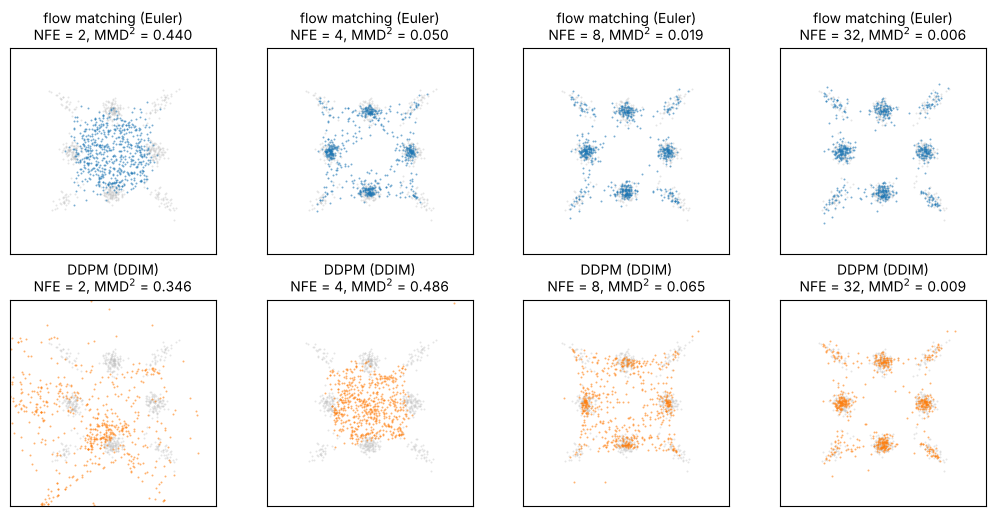

In [13]:
show_nfe = [2, 4, 8, 32]
fig, axes = plt.subplots(2, len(show_nfe), figsize=(2.6 * len(show_nfe), 5.2))
for j, nfe in enumerate(show_nfe):
    for i, (name, xs) in enumerate([
            ("flow matching (Euler)", ode_sample(model_vfn(fm_model), x1_eval, nfe)),
            ("DDPM (DDIM)", dm.ddim_sample(ddpm_model, schedule, x1_eval.shape, n_steps=nfe, x_T=x1_eval))]):
        ax = axes[i, j]
        dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.4)
        dm.scatter2d(xs[:N_PLOT], ax=ax, c=COL["fm"] if i == 0 else COL["ddpm"], s=2, alpha=0.6,
                     title=f"{name}\nNFE = {nfe}, MMD$^2$ = {mmd(xs):.3f}")
plt.tight_layout()
plt.show()

What to read off these two figures:

* The **exact-velocity** curve isolates pure *discretisation* error (no model error): it falls
  steadily with NFE towards the noise floor. The learned flow tracks it at small NFE (there,
  the time-stepping error dominates) and levels off at large NFE (where the model error dominates).
* With one Euler step every sampler collapses towards the data mean — the first step uses
  $v(x,1)=x-\mathbb E[x_0]$, so $x_0 = x_1 - v = \mathbb E[x_0]$. Curved paths need several steps.
* Heun is better per *step*, but compare at equal NFE: it typically wins only once the step is small enough for the second-order correction to help.
* With 1–2 NFE every sampler here is poor. From a handful of steps on (enough for recognisable
  samples), the flow model beats the DDPM model sampled with DDIM at equal NFE, and both converge to
  similar quality at large NFE. Section 5 shows that this is **not** because flow matching is a
  fundamentally different model: the gap comes from the time grid and the output parametrisation.

Finally, compare the learned and exact velocity fields directly.

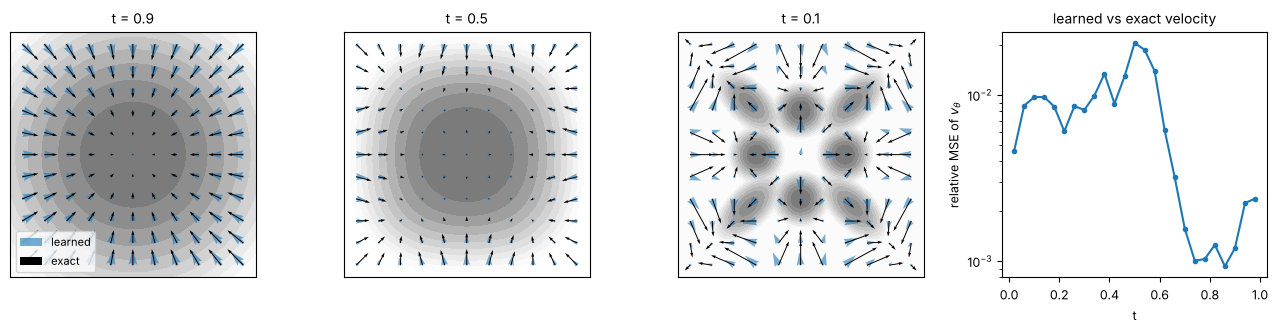

In [14]:
def velocity_error_vs_t(vfn, ts, n=N_EVAL, seed=5):
    """Relative error E||v_model - v_exact||^2 / E||v_exact||^2 on samples x_t ~ p_t, for each t."""
    g = torch.Generator().manual_seed(seed)
    errs = []
    for t in map(float, ts):
        x0, eps = gmm.sample(n, generator=g), torch.randn(n, 2, generator=g)
        xt = ((1 - t) * x0 + t * eps).to(device)
        v_true, _ = exact_velocity(gmm, xt, t)
        with torch.no_grad():
            v_hat = vfn(xt, t)
        errs.append((sq(v_hat, v_true).mean() / (v_true ** 2).sum(1).mean()).item())
    return np.array(errs)


ts_err = np.linspace(0.02, 0.98, 9 if FAST else 25)
err_fm = velocity_error_vs_t(model_vfn(fm_model), ts_err)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, t in zip(axes[:3], [0.9, 0.5, 0.1]):
    plot_density(ax, flow_marginal(gmm, t))
    plot_field(ax, model_vfn(fm_model), t, n=11, color=COL["fm"], width=0.012, alpha=0.6, label="learned")
    plot_field(ax, exact_vfn(gmm), t, n=11, color=COL["exact"], width=0.004, label="exact")
    ax.set_title(f"t = {t}"); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(loc="lower left")
axes[3].semilogy(ts_err, err_fm, "o-", color=COL["fm"], ms=3)
axes[3].set_xlabel("t"); axes[3].set_ylabel("relative MSE of $v_\\theta$")
axes[3].set_title("learned vs exact velocity")
plt.tight_layout()
plt.show()

Learned (thick blue) and exact (thin black) arrows almost coincide wherever $p_t$ has mass; visible
deviations appear only in low-density regions (e.g. the corners at small $t$) that training rarely
visits. The relative error (right) is small at every $t$. It is largest at intermediate times, where
the posterior over mixture components is still undecided and the field changes quickly across
space, and smallest at large $t$, where the field is nearly linear in $x$.

## 4 · Trajectories: why the learned flow is curved

Each training pair moves along a straight line, yet the ODE trajectories bend. The reason is
that **lines of different pairs cross**: at a crossing point the ODE must choose a single
velocity, and it takes the average (the posterior mean). Early on ($t\approx1$) the posterior over
$x_0$ is broad, so everybody heads for the data mean; later the posterior commits and the
particle turns towards "its" component.

Two ways to quantify straightness, for a path $x_t$ from $x_1$ to $x_0$:

* **length ratio** $\;\int_0^1\|\dot x_t\|dt\,/\,\|x_1-x_0\|$: 1 for a straight line;
* **Liu et al.'s straightness** $\;S=\int_0^1\mathbb E\,\|\dot x_t - (x_1-x_0)\|^2dt$: the variance of the
  velocity along the path around its time-average. $S=0$ iff every path is a straight line traversed at
  constant speed, which is exactly when a **single Euler step is exact**.

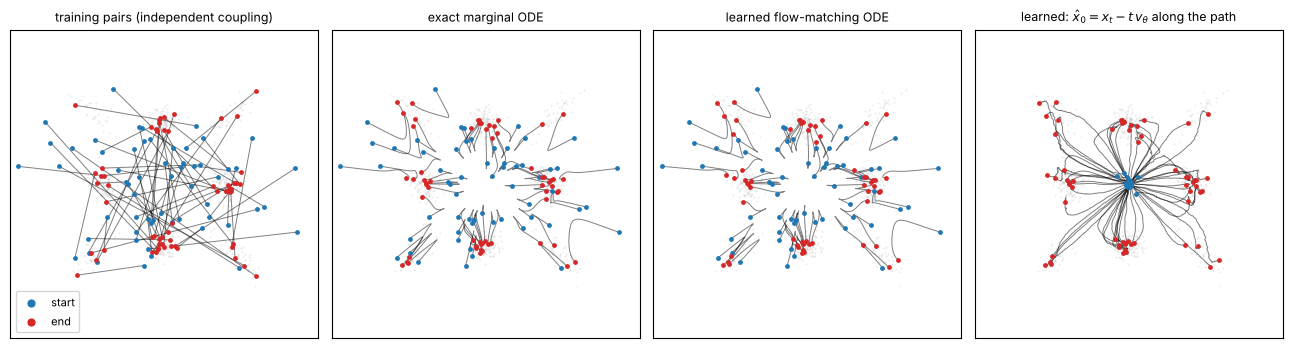

                 paths | length ratio | straightness S
             exact ODE |        1.965 |      1.073
        learned FM ODE |        1.948 |      1.046


In [15]:
def straightness(path):
    """(median length ratio, S) for Euler paths (S+1, N, d) on a uniform grid from t=1 to t=0."""
    steps = path[1:] - path[:-1]
    n = steps.shape[0]
    length = steps.norm(dim=-1).sum(0)
    chord = (path[-1] - path[0]).norm(dim=-1)
    v = -n * steps                                   # Euler velocities (dt = -1/n)
    v_avg = path[0] - path[-1]                       # time-average of v = x_1 - x_0
    S = ((v - v_avg) ** 2).sum(-1).mean()
    return (length / chord).median().item(), S.item()


def posterior_mean_path(path):
    """x0_hat = x_t - t v along an Euler path: the model's running estimate of the final sample."""
    n = path.shape[0] - 1
    v = -n * (path[1:] - path[:-1])
    t = torch.linspace(1, 0, n + 1)[:-1, None, None]
    return path[:-1] - t * v


N_PATH, PATH_STEPS = 60, 100
x1_path = torch.randn(N_PATH, 2, generator=torch.Generator().manual_seed(6)).to(device)
x0_pair = gmm.sample(N_PATH, generator=torch.Generator().manual_seed(7))
cond_paths = torch.stack([x1_path.cpu(), x0_pair])                  # the straight training lines
_, exact_paths = ode_sample(exact_vfn(gmm), x1_path, PATH_STEPS, return_path=True)
_, fm_paths = ode_sample(model_vfn(fm_model), x1_path, PATH_STEPS, return_path=True)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
panels = [("training pairs (independent coupling)", cond_paths),
          ("exact marginal ODE", exact_paths),
          ("learned flow-matching ODE", fm_paths),
          ("learned: $\\hat x_0 = x_t - t\\,v_\\theta$ along the path", posterior_mean_path(fm_paths))]
for ax, (title, p) in zip(axes, panels):
    dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.3)
    dm.plot_trajectories(p, ax=ax, n_show=N_PATH, lw=0.7, alpha=0.5)
    ax.set_title(title, fontsize=9)
axes[0].legend(loc="lower left", markerscale=2)
plt.tight_layout()
plt.show()

print(f"{'paths':>22} | length ratio | straightness S")
for name, p in [("exact ODE", exact_paths), ("learned FM ODE", fm_paths)]:
    r, S = straightness(p)
    print(f"{name:>22} | {r:12.3f} | {S:10.3f}")

Left: the straight training lines cross all over the place. The ODE trajectories (middle) cannot
cross, so they bend: they first move inwards, towards the data mean, then fan out to the components.
The learned flow reproduces the exact one closely. The right panel shows the model's running
guess $\hat x_0$ (blue dots at $t=1$): it starts *at the data mean for every particle* and then
commits — an evidence-accumulation picture familiar from Bayesian observer models. The
straightness numbers ($S>0$, length ratio $>1$) quantify why a single Euler step cannot work here.

## 5 · Flow matching is diffusion in disguise

**Same family of paths.** Every model in this tutorial uses a Gaussian path
$x_t = \alpha_t x_0 + \sigma_t\varepsilon$: VP diffusion has $(\alpha,\sigma)=(\sqrt{\bar\alpha},\sqrt{1-\bar\alpha})$,
flow matching has $(1-t,\,t)$. What matters is the signal-to-noise ratio $\alpha/\sigma$. Divide a VP
state by $\alpha+\sigma$:

$$\frac{x^{\rm VP}}{\alpha+\sigma} = \frac{\alpha}{\alpha+\sigma}x_0 + \frac{\sigma}{\alpha+\sigma}\varepsilon
= x^{\rm FM}_{t}\quad\text{with}\quad t = \frac{\sigma}{\alpha+\sigma}.$$

So a VP state *is* a flow-matching state, up to a known rescaling of $x$ and a change of the time
variable; both carry the same information about $x_0$ and have the same posterior.

**Translating predictions.** Since conditional expectation is linear, $x_t = (1-t)\hat x_0 + t\hat\varepsilon$
holds for the posterior means, and $v = \hat\varepsilon-\hat x_0$. Two linear equations, two unknowns:

$$\boxed{\hat x_0 = x_t - t\,v,\qquad \hat\varepsilon = x_t + (1-t)\,v,\qquad v = \frac{\hat\varepsilon - x_t}{1-t}}$$

**Loss weighting.** If $v_\theta$ has error $\delta$, then $\hat x_0$ has error $-t\delta$ and $\hat\varepsilon$
has error $(1-t)\delta$. Hence, per sample,

$$\|v_\theta - (\varepsilon - x_0)\|^2 = \frac{\|\hat\varepsilon_\theta-\varepsilon\|^2}{(1-t)^2} = \frac{\|\hat x_{0,\theta}-x_0\|^2}{t^2}:$$

flow matching is $\varepsilon$-prediction with weight $1/(1-t)^2$ (or $x_0$-prediction with weight $1/t^2$),
with a different distribution over noise levels than DDPM's uniform integer steps. It is closely
related to the **v-prediction** of Salimans & Ho (2022), which is $\frac{d x_\phi}{d\phi}$ for the
path $\alpha=\cos\phi,\ \sigma=\sin\phi$, just as $\varepsilon-x_0 = \frac{dx_t}{dt}$ for the straight path.

**DDIM is Euler.** A deterministic DDIM step (notebook 04) keeps the predictions
$(\hat x_0,\hat\varepsilon)$ fixed and moves to the next noise level: $x_s = \alpha_s\hat x_0 + \sigma_s\hat\varepsilon$.
In flow coordinates that is $z_s = (1-s)\hat x_0 + s\hat\varepsilon$; and an Euler step from $z_t=(1-t)\hat x_0+t\hat\varepsilon$
gives $z_t + (s-t)(\hat\varepsilon-\hat x_0) = (1-s)\hat x_0 + s\hat\varepsilon$ — **the same point**. The probability-flow
ODE of a diffusion model is a flow, and DDIM is its Euler discretisation in these coordinates.

Let's verify all of this numerically, first with the exact mixture.

In [16]:
# CHECK 1: dmtools' VP marginal (notebook 01) equals our flow marginal after x -> x / (alpha + sigma)
for ab in [0.9, 0.5, 0.1]:
    alpha, sigma = math.sqrt(ab), math.sqrt(1 - ab)
    t, c = sigma / (alpha + sigma), alpha + sigma
    lp_vp = gmm.noised(ab).log_prob(xq)
    lp_fm = flow_marginal(gmm, t).log_prob(xq / c) - gmm.d * math.log(c)    # change of variables
    print(f"abar = {ab}: t = {t:.3f}, max |log p_VP - log p_FM| = {(lp_vp - lp_fm).abs().max():.1e}")
    assert torch.allclose(lp_vp, lp_fm, atol=1e-3)

# CHECK 2: x0_hat = x - t v and eps_hat = x + (1-t) v agree with Tweedie's formulas built from the score
for t in [0.2, 0.5, 0.8]:
    v, _ = exact_velocity(gmm, xq, t)
    score = flow_marginal(gmm, t).score(xq)
    x0_tweedie, eps_tweedie = (xq + t ** 2 * score) / (1 - t), -t * score
    e1, e2 = (xq - t * v - x0_tweedie).abs().max().item(), (xq + (1 - t) * v - eps_tweedie).abs().max().item()
    print(f"t = {t}: |x0_hat - Tweedie| = {e1:.1e}, |eps_hat - Tweedie| = {e2:.1e}")
    assert max(e1, e2) < 1e-3

abar = 0.9: t = 0.250, max |log p_VP - log p_FM| = 7.6e-06
abar = 0.5: t = 0.500, max |log p_VP - log p_FM| = 3.8e-06
abar = 0.1: t = 0.750, max |log p_VP - log p_FM| = 1.9e-06
t = 0.2: |x0_hat - Tweedie| = 2.4e-07, |eps_hat - Tweedie| = 9.5e-07
t = 0.5: |x0_hat - Tweedie| = 4.8e-07, |eps_hat - Tweedie| = 9.5e-07
t = 0.8: |x0_hat - Tweedie| = 2.1e-06, |eps_hat - Tweedie| = 4.8e-07


**Converting trained models in both directions.** With the dictionary above we can wrap

* the **flow model as an $\varepsilon$-predictor** in DDPM's discrete VP time $k$ (so that `dm.ddpm_sample` and
  `dm.ddim_sample` can sample it): map $k\mapsto(\alpha_k,\sigma_k)\mapsto t=\sigma_k/(\alpha_k+\sigma_k)$, rescale
  $z = x/(\alpha_k+\sigma_k)$, return $\hat\varepsilon = z + (1-t)v_\theta(z,t)$;
* the **DDPM model as a velocity field** in flow coordinates: map $t\mapsto$ log-SNR $\lambda=2\log\frac{1-t}{t}\mapsto$ a
  (fractional) step $k$ by interpolating the schedule's log-SNR table, rescale $x = z/\sqrt{(1-t)^2+t^2}$, and
  return $v = (\hat\varepsilon-z)/(1-t)$. The DDPM model only knows log-SNRs inside its schedule, so $t$ is clamped to that range.

These wrappers are written for the 2-D MLP (coefficients of shape `(B, 1)`); for images they would need `(B, 1, 1, 1)`.

In [17]:
class FlowAsEps(nn.Module):
    """A flow-matching velocity model exposed as a DDPM eps-model eps(x_vp, k, y) in discrete VP time."""

    def __init__(self, flow_model, schedule):
        super().__init__()
        self.flow, self.schedule = flow_model, schedule
        self.n_classes = flow_model.n_classes            # so dmtools' guidance code can find the null label

    def forward(self, x, k, y=None):
        ab = self.schedule.alpha_bars[k.long()][:, None]
        alpha, sigma = ab.sqrt(), (1 - ab).sqrt()
        t = sigma / (alpha + sigma)                      # same signal-to-noise ratio
        z = x / (alpha + sigma)                          # VP state -> flow state
        v = self.flow(z, time_input(t[:, 0]), y)
        return z + (1 - t) * v                           # eps_hat (identical in both coordinates)


class EpsAsFlow:
    """A DDPM eps-model exposed as a velocity field v(z, t) in flow-matching coordinates."""

    def __init__(self, eps_model, schedule):
        self.model = eps_model
        ab = schedule.alpha_bars.double().cpu().numpy()
        lam = np.log(ab) - np.log1p(-ab)                 # log-SNR, decreasing in k
        self.lam_table, self.k_table = lam[::-1].copy(), np.arange(schedule.T, dtype=np.float64)[::-1].copy()
        t_of = lambda a: math.sqrt(1 - a) / (math.sqrt(a) + math.sqrt(1 - a))
        self.t_min, self.t_max = t_of(ab[0]), t_of(ab[-1])   # the SNR range the model was trained on

    def __call__(self, z, t):
        t = min(max(t, self.t_min), self.t_max)
        k = float(np.interp(2 * math.log((1 - t) / t), self.lam_table, self.k_table))   # fractional step
        x = z / math.sqrt((1 - t) ** 2 + t ** 2)         # flow state -> VP state
        eps = self.model(x, torch.full((z.shape[0],), k, device=z.device))
        return (eps - z) / (1 - t)


def ddim_grid_in_flow_time(n_steps):
    """dm.ddim_sample's integer steps k (uniform in k, notebook 04) and the matching flow times t."""
    ks = np.unique(np.linspace(0, schedule.T - 1, n_steps).round().astype(int))[::-1]
    ab = schedule.alpha_bars.double().cpu().numpy()[ks]
    return ks, np.sqrt(1 - ab) / (np.sqrt(ab) + np.sqrt(1 - ab))


# CHECK 3: Euler on the converted DDPM model, on the image of DDIM's own time grid, reproduces dm.ddim_sample
n_ddim = 10
ks, t_ks = ddim_grid_in_flow_time(n_ddim)
xT = torch.randn(N_EVAL, 2, generator=torch.Generator().manual_seed(8)).to(device)
with torch.no_grad():
    x_ddim = dm.ddim_sample(ddpm_model, schedule, xT.shape, n_steps=n_ddim, x_T=xT)
    ab_T = schedule.alpha_bars[ks[0]].item()
    z_T = xT / (math.sqrt(ab_T) + math.sqrt(1 - ab_T))                     # same starting point, flow coords
    x_euler = ode_sample(EpsAsFlow(ddpm_model, schedule), z_T, ts=list(t_ks) + [0.0])
diff = (x_ddim - x_euler).abs().max().item()
print(f"DDIM ({n_ddim} steps) vs Euler on the converted model: max |difference| = {diff:.1e}")
assert diff < 1e-3

DDIM (10 steps) vs Euler on the converted model: max |difference| = 5.4e-05


DDIM and Euler-in-flow-coordinates produce the same samples to float precision. Now the other
direction: sample the **flow-matching model with the DDPM machinery** of notebooks 02 and 04,
including the *stochastic* ancestral sampler — a flow model can be sampled stochastically too.

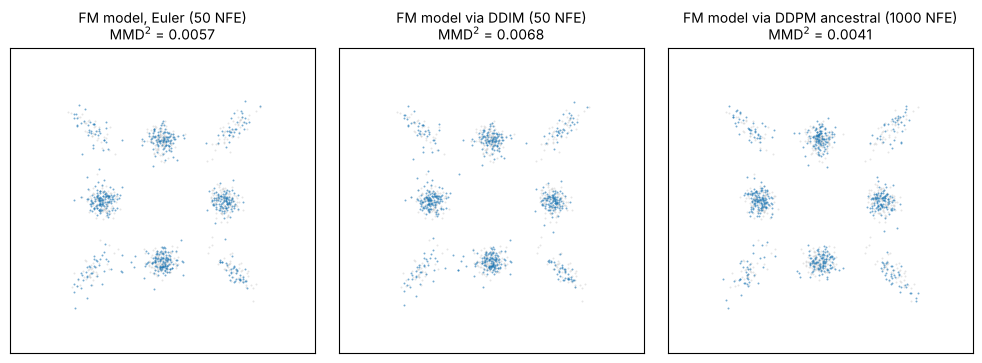

In [18]:
fm_as_eps = FlowAsEps(fm_model, schedule)
with torch.no_grad():
    samples = {"FM model, Euler (50 NFE)": ode_sample(model_vfn(fm_model), x1_eval, 50),
               "FM model via DDIM (50 NFE)": dm.ddim_sample(fm_as_eps, schedule, x1_eval.shape, n_steps=50, x_T=x1_eval),
               "FM model via DDPM ancestral (1000 NFE)": dm.ddpm_sample(fm_as_eps, schedule, x1_eval.shape)}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, (name, xs) in zip(axes, samples.items()):
    dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.4)
    dm.scatter2d(xs[:N_PLOT], ax=ax, c=COL["fm"], s=2, alpha=0.6, title=f"{name}\nMMD$^2$ = {mmd(xs):.4f}")
plt.tight_layout()
plt.show()

All three samplers give good samples from the same flow-matching network: the
"diffusion vs flow" distinction is about *how a model is trained and parametrised*, not about
which sampler you may use. (The stochastic sampler costs 20× more evaluations, but its injected
noise can also correct some accumulated error — the usual stochastic-vs-deterministic trade-off.)

**So where did the few-step gap of Section 3 come from?** Two suspects: (i) the *time grid* —
DDIM's grid is uniform in the integer step $k$, which for the linear schedule packs most steps at
high noise — and (ii) the *output parametrisation*. To isolate them, sample the converted DDPM model
with exactly the flow model's Euler sampler on a uniform-in-$t$ grid, and compare the velocity
errors of both networks as a function of $t$.

8-step DDIM grid expressed in flow time t: [0.994 0.976 0.93  0.838 0.702 0.535 0.331 0.01 ] -> 0
8-step uniform flow grid:                  [1.    0.875 0.75  0.625 0.5   0.375 0.25  0.125] -> 0


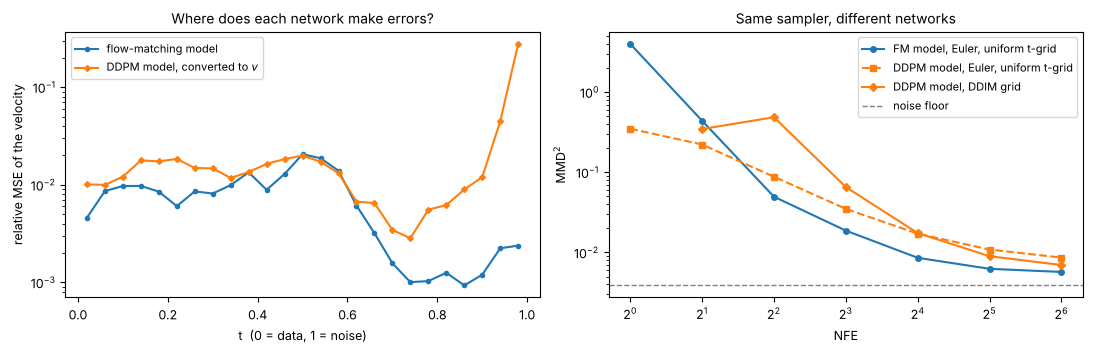

In [19]:
eps_as_flow = EpsAsFlow(ddpm_model, schedule)
err_ddpm = velocity_error_vs_t(eps_as_flow, ts_err)
quality["ddpm_euler"] = [mmd(ode_sample(eps_as_flow, x1_eval, nfe)) for nfe in NFES]

print("8-step DDIM grid expressed in flow time t:", np.round(ddim_grid_in_flow_time(8)[1], 3), "-> 0")
print("8-step uniform flow grid:                 ", np.round(np.linspace(1, 0, 9)[:-1], 3), "-> 0")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].semilogy(ts_err, err_fm, "o-", color=COL["fm"], ms=3, label="flow-matching model")
axes[0].semilogy(ts_err, err_ddpm, "D-", color=COL["ddpm"], ms=3, label="DDPM model, converted to $v$")
axes[0].set_xlabel("t  (0 = data, 1 = noise)"); axes[0].set_ylabel("relative MSE of the velocity")
axes[0].set_title("Where does each network make errors?"); axes[0].legend()
for k, lab, c, m in [("fm_euler", "FM model, Euler, uniform t-grid", COL["fm"], "o-"),
                     ("ddpm_euler", "DDPM model, Euler, uniform t-grid", COL["ddpm"], "s--"),
                     ("ddim", "DDPM model, DDIM grid", COL["ddpm"], "D-")]:
    axes[1].plot(NFES, quality[k], m, color=c, ms=4, label=lab)
axes[1].axhline(MMD_FLOOR, color="0.5", lw=1, ls="--", label="noise floor")
axes[1].set_xscale("log", base=2); axes[1].set_yscale("log")
axes[1].set_xlabel("NFE"); axes[1].set_ylabel("MMD$^2$"); axes[1].set_title("Same sampler, different networks")
axes[1].legend()
plt.tight_layout()
plt.show()

Left: converted to velocities, the $\varepsilon$-model's errors are amplified by $1/(1-t)$ near pure
noise ($v=(\hat\varepsilon - x_t)/(1-t)$): a small error in $\hat\varepsilon$ becomes a large error in the
direction of motion, exactly where a few-step sampler takes its first and largest step. The flow
model predicts $v$ directly and has no such blow-up.

Right: grid and parametrisation interact. DDIM's grid (printed above) is uniform in the integer step
$k$, which for the linear schedule means many small steps near $t=1$ — exactly where the $\varepsilon$-model's
velocity is unreliable — followed by one or two huge steps across the low-noise region. With very few
steps that wastes evaluations, and the uniform grid serves the DDPM network better; with more steps the
small high-noise steps of DDIM's grid pay off for it. The flow network on its uniform grid is the
best (or tied) at most budgets. (At 1–2 NFE every method is poor, so ignore the ranking there.)
The lesson generalises: **put small steps where the network's velocity is least reliable**, and
prefer a parametrisation that is reliable where your sampler takes big steps.

**Loss weighting across noise levels.** Writing every objective as a weighted
$\varepsilon$-MSE per unit of log-SNR $\lambda$ makes them comparable (Kingma & Gao 2023). For flow matching with
$t\sim U(0,1)$: $\lambda = 2\log\frac{1-t}{t}$, $|dt/d\lambda| = t(1-t)/2$, and weight $1/(1-t)^2$, so the
effective weight is $\frac{t}{2(1-t)} = \tfrac12 e^{-\lambda/2}$. For DDPM's simple loss it is just the density of
$\lambda$ under uniform integer steps. SD3 samples $t$ from a **logit-normal**, $t=\mathrm{sigmoid}(n)$, $n\sim\mathcal N(0,1)$.

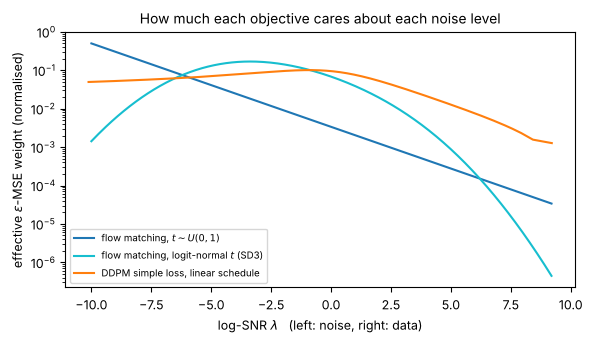

In [20]:
lam = np.linspace(-10, 10, 400)
t_of_lam = 1 / (1 + np.exp(lam / 2))                       # inverse of lambda = 2 log((1-t)/t)
w_fm = 0.5 * np.exp(-lam / 2)                               # uniform t, eps-weight 1/(1-t)^2
w_lognorm = np.exp(-(lam / 2) ** 2 / 2) / math.sqrt(2 * math.pi) / 2 / (1 - t_of_lam) ** 2
lam_ddpm = schedule.log_snr.cpu().numpy()                   # one value per integer step, decreasing
dens_ddpm = 1.0 / (len(lam_ddpm) * np.abs(np.gradient(lam_ddpm)))   # density of lambda under uniform k

fig, ax = plt.subplots(figsize=(6, 3.5))
for x_l, w, lab, c in [(lam, w_fm, "flow matching, $t\\sim U(0,1)$", COL["fm"]),
                       (lam, w_lognorm, "flow matching, logit-normal $t$ (SD3)", "tab:cyan"),
                       (lam_ddpm, dens_ddpm, "DDPM simple loss, linear schedule", COL["ddpm"])]:
    m = (x_l >= lam_ddpm.min()) & (x_l <= lam_ddpm.max())   # normalise over the range DDPM covers
    area = abs(np.sum(0.5 * (w[m][1:] + w[m][:-1]) * np.diff(x_l[m])))   # trapezoid rule
    ax.semilogy(x_l[m], w[m] / area, color=c, label=lab)
ax.set_xlabel("log-SNR $\\lambda$   (left: noise, right: data)")
ax.set_ylabel("effective $\\varepsilon$-MSE weight (normalised)")
ax.set_title("How much each objective cares about each noise level"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

Uniform-$t$ flow matching puts exponentially more weight on noisy inputs (low $\lambda$) than DDPM's
simple loss. SD3's logit-normal sampling instead concentrates the weight on intermediate noise levels
(its density in $t$ peaks at $t=0.5$, i.e. $\lambda=0$; the $1/(1-t)^2$ factor shifts the effective
weight somewhat towards the noisy side) and suppresses both extremes; Esser et al. found this
best for image quality.
Taken together: flow matching = a Gaussian diffusion with a particular time parametrisation, output
parametrisation ($v$), and loss weighting — which is exactly why it slots into existing diffusion
tooling (samplers, guidance, distillation) so easily.

## 6 · Rectified flow: straightening by "reflow"

The curvature comes from the *coupling* between noise and data: pairing them independently makes
training lines cross. Liu, Gong & Liu (2023) observe that the trained ODE itself defines a much better
coupling: draw $\varepsilon$, integrate to get $\hat x_0=\mathrm{ODE}_{1\to0}(\varepsilon)$, and **retrain on the pairs
$(\hat x_0,\varepsilon)$**. The new coupling is deterministic and has the same marginals; they prove that
this "rectification" does not increase any convex transport cost and that repeated reflows make paths
increasingly straight. Practicalities: generating pairs costs one accurate ODE solve per pair; any
error of the first model is baked into the pairs (so the sample-quality floor can only get worse);
and one usually fine-tunes from the first model rather than starting from scratch.

In [21]:
N_PAIRS = 2_000 if FAST else 20_000
REFLOW_STEPS = 150 if FAST else STEPS // 2

eps_pairs = torch.randn(N_PAIRS, 2, generator=torch.Generator().manual_seed(9)).to(device)
t0 = time.time()
x0_pairs = ode_sample(model_vfn(fm_model), eps_pairs, 25, method="heun")      # 50 NFE: accurate solve
print(f"generated {N_PAIRS} (noise, sample) pairs in {time.time() - t0:.0f}s")


def coupled_pairs(x0, eps):
    """Reflow: sample from a fixed, deterministic coupling (x0_i, eps_i)."""
    def sample(bs):
        idx = torch.randint(0, len(x0), (bs,), device=x0.device)
        return x0[idx], eps[idx]
    return sample


rf_model = copy.deepcopy(fm_model)                   # fine-tune the 1-rectified flow ...
for p in rf_model.parameters():                      # (EMA copies are frozen; unfreeze)
    p.requires_grad_(True)
dm.seed_everything(1)
t0 = time.time()
rf_model, rf_losses = train_flow(rf_model, coupled_pairs(x0_pairs, eps_pairs), steps=REFLOW_STEPS,
                                 lr=LR / 2, log_every=REFLOW_STEPS // 3)
print(f"reflow trained in {time.time() - t0:.0f}s; final loss {rf_losses[-200:].mean():.4f} "
      f"(vs {fm_losses[-200:].mean():.4f} for the first model)")

generated 20000 (noise, sample) pairs in 7s


  step   833 | loss 0.0262


  step  1666 | loss 0.0013


  step  2499 | loss 0.0007
reflow trained in 25s; final loss 0.0005 (vs 1.4231 for the first model)


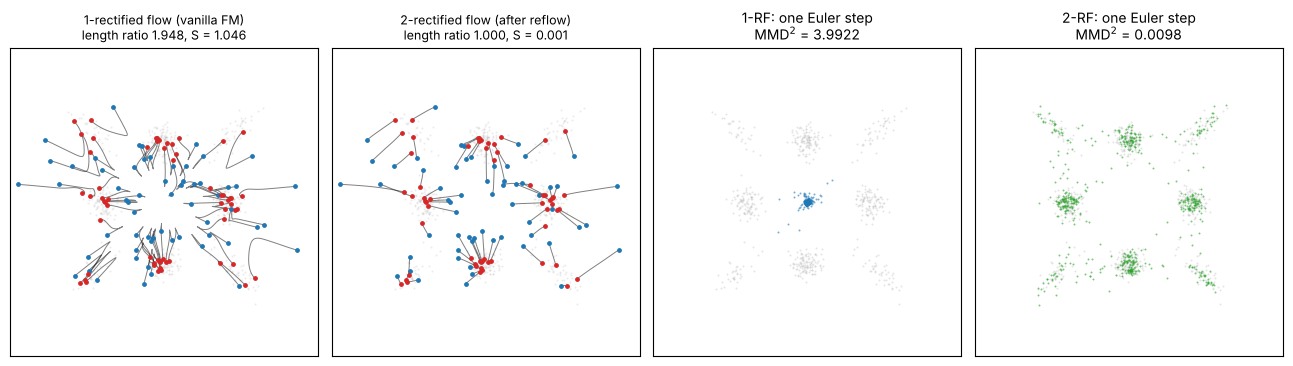

In [22]:
_, rf_paths = ode_sample(model_vfn(rf_model), x1_path, PATH_STEPS, return_path=True)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, (title, p) in zip(axes[:2], [("1-rectified flow (vanilla FM)", fm_paths), ("2-rectified flow (after reflow)", rf_paths)]):
    dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.3)
    dm.plot_trajectories(p, ax=ax, n_show=N_PATH, lw=0.7, alpha=0.5)
    r, S = straightness(p)
    ax.set_title(f"{title}\nlength ratio {r:.3f}, S = {S:.3f}", fontsize=9)
for ax, (name, model, c) in zip(axes[2:], [("1-RF", fm_model, COL["fm"]), ("2-RF", rf_model, COL["reflow"])]):
    xs = ode_sample(model_vfn(model), x1_eval, 1)
    dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.4)
    dm.scatter2d(xs[:N_PLOT], ax=ax, c=c, s=2, alpha=0.6, title=f"{name}: one Euler step\nMMD$^2$ = {mmd(xs):.4f}")
plt.tight_layout()
plt.show()

After one reflow the trajectories are nearly straight lines, so a single Euler step lands almost
where the full ODE would: one network evaluation now produces a sensible sample, instead of
collapsing onto the data mean. The reflow training loss also drops far below the first model's
floor $C$: with a deterministic, nearly non-crossing coupling there is little posterior
variance left in $\varepsilon - x_0$ given $x_t$.

## 7 · Mini-batch optimal-transport couplings

Reflow fixes the coupling *after* training. Tong et al. (2023) (and Pooladian et al. 2023) choose a better
coupling *during* training: within each batch, re-pair noise and data to minimise the total squared
distance $\sum_i\|x_0^{(i)}-\varepsilon^{(\pi(i))}\|^2$ over permutations $\pi$ — a linear assignment problem
solved exactly by the Hungarian algorithm (`scipy.optimize.linear_sum_assignment`, $O(B^3)$, cheap for
$B\lesssim 10^3$).

* **Marginals are preserved**: the batch's noise vectors are only permuted, so a randomly chosen pair still has
  $x_0\sim p_{\rm data}$ and $\varepsilon\sim\mathcal N(0,I)$ — the theory of Section 1 holds for *any* coupling with these marginals.
* **Why straighter**: for the exact quadratic-cost OT plan, straight lines between coupled points never cross
  (cyclical monotonicity), so the marginal velocity equals the per-pair velocity and the ODE paths are straight.
  A mini-batch only approximates the OT plan, and less well in high dimension, where a batch covers the space sparsely.

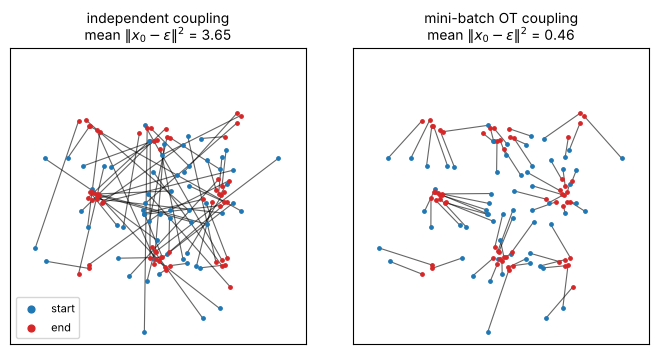

In [23]:
def ot_pairs(x_data):
    """Mini-batch OT-CFM: re-pair noise and data within each batch by optimal assignment."""
    def sample(bs):
        x0 = x_data[torch.randint(0, len(x_data), (bs,), device=x_data.device)]
        eps = torch.randn_like(x0)
        cost = torch.cdist(x0, eps).pow(2).cpu().numpy()
        _, col = linear_sum_assignment(cost)             # rows come back as 0..bs-1
        return x0, eps[torch.as_tensor(col, device=x0.device)]
    return sample


# visualise one small batch under both couplings
torch.manual_seed(10)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, (name, sampler) in zip(axes, [("independent coupling", independent_pairs(data_dev)),
                                      ("mini-batch OT coupling", ot_pairs(data_dev))]):
    torch.manual_seed(10)                                # same batch for both panels
    x0_b, eps_b = sampler(64)
    dm.plot_trajectories(torch.stack([eps_b.cpu(), x0_b.cpu()]), ax=ax, n_show=64, lw=0.8, alpha=0.6)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}\nmean $\\|x_0-\\varepsilon\\|^2$ = {sq(x0_b, eps_b).mean():.2f}")
axes[0].legend(loc="lower left", markerscale=2)
plt.tight_layout()
plt.show()

Same 64 noise vectors and data points; only the pairing differs. The OT pairing removes most crossings and
shortens the average displacement. Train exactly as before, only with the new pair sampler:

In [24]:
dm.seed_everything(0)
t0 = time.time()
ot_model, ot_losses = train_flow(make_mlp(), ot_pairs(data_dev), log_every=STEPS // 4)
print(f"OT-CFM trained in {time.time() - t0:.0f}s; final loss {ot_losses[-200:].mean():.4f}")

  step  1250 | loss 0.0642


  step  2500 | loss 0.0395


  step  3750 | loss 0.0376


  step  5000 | loss 0.0359
OT-CFM trained in 93s; final loss 0.0358


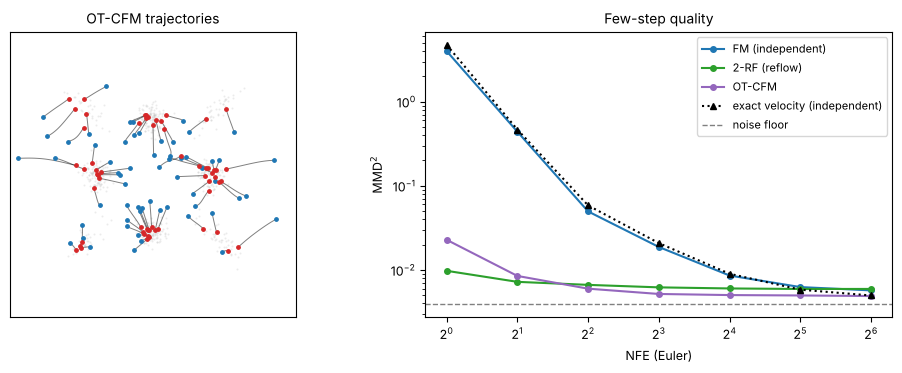

             model | length ratio | straightness S | MMD@1 | MMD@2 | MMD@4 | MMD@8 | MMD@16 | MMD@32 | MMD@64
  FM (independent) |        1.948 |          1.046 | 3.9922 | 0.4396 | 0.0496 | 0.0187 | 0.0086 | 0.0063 | 0.0057
     2-RF (reflow) |        1.000 |          0.001 | 0.0098 | 0.0072 | 0.0067 | 0.0062 | 0.0060 | 0.0059 | 0.0059
            OT-CFM |        1.001 |          0.005 | 0.0228 | 0.0085 | 0.0060 | 0.0052 | 0.0050 | 0.0050 | 0.0049


In [25]:
_, ot_paths = ode_sample(model_vfn(ot_model), x1_path, PATH_STEPS, return_path=True)
models = {"FM (independent)": (fm_model, COL["fm"], fm_paths),
          "2-RF (reflow)": (rf_model, COL["reflow"], rf_paths),
          "OT-CFM": (ot_model, COL["ot"], ot_paths)}
few_nfe = {name: [mmd(ode_sample(model_vfn(m), x1_eval, nfe)) for nfe in NFES] for name, (m, _, _) in models.items()}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
dm.scatter2d(test[:N_PLOT], ax=axes[0], c=COL["data"], s=2, alpha=0.3)
dm.plot_trajectories(ot_paths, ax=axes[0], n_show=N_PATH, lw=0.7, alpha=0.5)
axes[0].set_title("OT-CFM trajectories")
for name, (_, c, _) in models.items():
    axes[1].plot(NFES, few_nfe[name], "o-", color=c, ms=4, label=name)
axes[1].plot(NFES, quality["exact_euler"], "^:", color=COL["exact"], ms=4, label="exact velocity (independent)")
axes[1].axhline(MMD_FLOOR, color="0.5", lw=1, ls="--", label="noise floor")
axes[1].set_xscale("log", base=2); axes[1].set_yscale("log")
axes[1].set_xlabel("NFE (Euler)"); axes[1].set_ylabel("MMD$^2$"); axes[1].set_title("Few-step quality")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"{'model':>18} | length ratio | straightness S | " + " | ".join(f"MMD@{n}" for n in NFES))
for name, (_, _, p) in models.items():
    r, S = straightness(p)
    print(f"{name:>18} | {r:12.3f} | {S:14.3f} | " + " | ".join(f"{q:6.4f}" for q in few_nfe[name]))

Both remedies straighten the flow and make 1–2-step Euler sampling usable. Note the shape of the
reflow curve: once the paths are straight, extra steps buy almost nothing, and its many-step quality is
capped by the first model, whose samples it was trained on. The two remedies come at very different costs:
reflow needs a trained model, an ODE solve per training pair and a second training run, and inherits the
first model's errors; OT-CFM costs one assignment per batch and nothing else — but its benefit shrinks
as the dimension grows relative to the batch size, which is why large image models do not rely on it
alone (and why few-step distillation methods such as consistency models or adversarial diffusion
distillation exist). In 2-D, batches of 256 already give a good approximation of the OT plan.

## 8 · Flow matching in practice

**Where it is used.** Stable Diffusion 3 (Esser et al. 2024) and Flux are rectified-flow transformers in the
latent space of an autoencoder (notebook 09); flow matching is also used in video (e.g. Meta's Movie Gen),
speech (Voicebox) and robot policies (e.g. $\pi_0$; see notebook 10). The recipe is this notebook's, with a
bigger network.

**The knobs that matter.**
* *Timestep distribution.* Uniform $t$ is a choice, not a law. SD3 found logit-normal sampling of $t$ (centred
  at $t=0.5$) best, i.e. more training signal at intermediate noise (see the weighting plot in Section 5). For
  higher resolutions they also *shift* $t$ towards noise, $t\mapsto \frac{s\,t}{1+(s-1)t}$ with $s>1$, because
  more pixels make the same $t$ effectively less noisy.
* *Sampler and steps.* Plain Euler with roughly 20–50 uniform or shifted steps is the default for large
  flow models; Heun / higher-order solvers help when NFE is very limited. Distilled or reflowed
  models (e.g. Flux "schnell", InstaFlow) sample in 1–4 steps.
* *Parametrisation.* Predicting $v$ is well conditioned at both ends of the path (Section 5), one reason the
  community moved away from pure $\varepsilon$-prediction for few-step sampling.
* *Guidance.* Classifier-free guidance (notebook 06) carries over verbatim:
  $v_w = v_\theta(x,t,\varnothing) + w\,\big(v_\theta(x,t,y) - v_\theta(x,t,\varnothing)\big)$. Because $v = (\hat\varepsilon - x)/(1-t)$
  is an affine function of $\hat\varepsilon$ with an $x$-term that does not depend on the label, guiding $v$ is
  *identical* to guiding $\hat\varepsilon$ (or $\hat x_0$, or the score) with the same $w$.

Let's train a class-conditional flow model on `dm.labelled_gmm()` (three classes; class 1 sits in
the middle, overlapping the others), with label dropout, and check the guidance identity against dmtools'
own $\varepsilon$-space CFG implementation via the `FlowAsEps` wrapper.

In [26]:
lgmm, comp_class = dm.labelled_gmm()
x_lab, k_lab = lgmm.sample(N_TRAIN, return_labels=True, generator=torch.Generator().manual_seed(11))
y_lab = torch.as_tensor(comp_class)[k_lab]
x_lab, y_lab = x_lab.to(device), y_lab.to(device)


def labelled_pairs(x, y):
    """Independent coupling plus each data point's class label."""
    def sample(bs):
        idx = torch.randint(0, len(x), (bs,), device=x.device)
        return x[idx], torch.randn_like(x[idx]), y[idx]
    return sample


dm.seed_everything(0)
t0 = time.time()
cond_model, _ = train_flow(make_mlp(n_classes=3), labelled_pairs(x_lab, y_lab), p_uncond=0.2,
                           steps=STEPS if FAST else STEPS * 2 // 3)
print(f"conditional flow model trained in {time.time() - t0:.0f}s")


def guided_vfn(model, label, w):
    """CFG on velocities: v_uncond + w (v_cond - v_uncond)."""
    def vfn(x, t):
        tt = torch.full((x.shape[0],), time_input(t), device=x.device)
        y = torch.full((x.shape[0],), label, device=x.device, dtype=torch.long)
        v_c, v_u = model(x, tt, y), model(x, tt, torch.full_like(y, model.n_classes))
        return v_u + w * (v_c - v_u)
    return vfn


# CHECK: guided velocity -> eps equals dmtools' CFG computed in eps-space on the wrapped model
k_chk, w_chk = 400, 3.0
ab = schedule.alpha_bars[k_chk].item()
alpha, sigma = math.sqrt(ab), math.sqrt(1 - ab)
t_chk = sigma / (alpha + sigma)
x_vp = torch.randn(256, 2, device=device)
with torch.no_grad():
    eps_dm, _ = dm.model_predictions(FlowAsEps(cond_model, schedule), x_vp, k_chk, schedule,
                                     y=torch.full((256,), 1, device=device, dtype=torch.long), guidance_scale=w_chk)
    z = x_vp / (alpha + sigma)
    eps_from_v = z + (1 - t_chk) * guided_vfn(cond_model, 1, w_chk)(z, t_chk)
gdiff = (eps_dm - eps_from_v).abs().max().item()
print(f"guiding v vs guiding eps (dmtools): max |difference| = {gdiff:.1e}")
assert gdiff < 1e-3

conditional flow model trained in 32s
guiding v vs guiding eps (dmtools): max |difference| = 2.4e-06


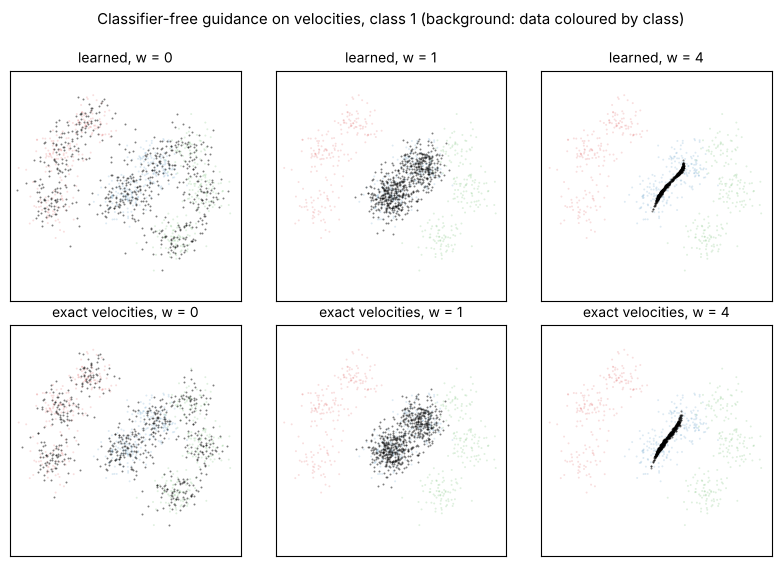

In [27]:
target = 1                                              # the central, ambiguous class
oracle_c = lgmm.subset(np.where(comp_class == target)[0])   # exact class-conditional distribution


def exact_guided_vfn(w):
    """The same guidance rule applied to the exact unconditional and class-conditional velocities."""
    def vfn(x, t):
        v_u = exact_velocity(lgmm, x, t)[0]
        return v_u + w * (exact_velocity(oracle_c, x, t)[0] - v_u)
    return vfn


ws = [0.0, 1.0, 4.0]
class_cols = np.array(["tab:red", "tab:blue", "tab:green"])
x_bg, y_bg = x_lab[:N_PLOT].cpu(), y_lab[:N_PLOT].cpu().numpy()
fig, axes = plt.subplots(2, len(ws), figsize=(2.7 * len(ws), 5.6))
for j, w in enumerate(ws):
    for i, (name, vfn) in enumerate([("learned", guided_vfn(cond_model, target, w)),
                                     ("exact velocities", exact_guided_vfn(w))]):
        xs = ode_sample(vfn, x1_eval[:N_PLOT], 32)
        ax = axes[i, j]
        dm.scatter2d(x_bg, ax=ax, c=class_cols[y_bg], s=2, alpha=0.15, lim=3.5)
        dm.scatter2d(xs, ax=ax, c="k", s=2, alpha=0.5, lim=3.5, title=f"{name}, w = {w:g}")
plt.suptitle(f"Classifier-free guidance on velocities, class {target} (background: data coloured by class)", y=1.0)
plt.tight_layout()
plt.show()

Top row: the trained conditional flow; bottom row: the same guidance rule applied to the exact
conditional and unconditional velocities — the two rows agree closely. $w=0$ gives the unconditional
mixture and $w=1$ the class-1 distribution. For $w>1$ samples are pushed away from everything the other
classes could explain: diversity collapses and, at large $w$, the samples pile up on a thin ridge
between the two class-1 components rather than on the components themselves. Guidance is a heuristic:
the guided field is not the velocity of the noised version of any fixed target distribution, which is
why strong guidance distorts samples (notebook 06, Section 4, analyses this for scores; since guiding
$v$ is literally the same operation, the same analysis applies).

## Exercises

**Exercise 1 (timestep distribution).** Retrain the flow model with SD3's logit-normal timesteps,
`t_sampler=lambda bs, dev: torch.sigmoid(torch.randn(bs, device=dev))`, and recompute
`velocity_error_vs_t` and the MMD-vs-NFE curve. *Predict first:* at which $t$ should the error go down,
and where up?
<details><summary>Hint / solution</summary>
The logit-normal puts few samples near $t=0$ and $t=1$, so errors drop in the middle and rise at the ends —
mostly near $t\to0$, where the field is sharpest. For this 2-D mixture with thin components, fine detail
near the data matters, so uniform sampling may well be as good or better; in high-resolution images the
ends are "easy" and the middle carries the perceptually relevant structure, which is why SD3 prefers it.
</details>

**Exercise 2 (non-uniform sampling grids).** Pass an explicit grid to `ode_sample(..., ts=...)` using the SD3
shift $t\mapsto st/(1+(s-1)t)$ applied to a uniform grid, for $s\in\{1/3, 1, 3\}$, and compare MMD at 4 and 8
Euler steps for `fm_model`.
<details><summary>Hint / solution</summary>
`u = np.linspace(1, 0, n + 1); ts = s * u / (1 + (s - 1) * u)`. $s>1$ spends more steps at high noise,
$s<1$ more near the data. Section 3's error plot (error grows as $t\to0$) and the curvature of the paths near
the components suggest that, for this dataset, steps near the data are worth more.
</details>

**Exercise 3 (reflow again).** Generate new pairs with `rf_model` and train a 3-rectified flow. Does
straightness keep improving? What happens to the MMD at 64 NFE compared with the 1- and 2-rectified flows?
<details><summary>Hint / solution</summary>
Straightness improves with diminishing returns (Liu et al. show the sum of straightness over reflows is bounded).
The many-step MMD cannot improve and usually degrades slightly: each reflow trains on samples of the previous
model, so its errors accumulate.
</details>

**Exercise 4 (OT batch size and dimension).** Retrain OT-CFM with `bs=16` and `bs=1024` and compare
straightness. Then embed the data in $d=16$ dimensions (append 14 coordinates of small Gaussian noise;
you will need `make_mlp` with `data_dim=16`) and repeat. How does the benefit of OT pairing change?
<details><summary>Hint / solution</summary>
Larger batches approximate the OT plan better, giving straighter paths. In higher dimension a batch of fixed size
covers the space much more sparsely, the mini-batch plan is far from the population OT plan, and the gain
shrinks — the reason OT-CFM shines on low-dimensional problems.
</details>

**Exercise 5 (flow matching on MNIST, GPU recommended).** Train `dm.UNet(**dm.MNIST_RECIPE)` with `train_flow`
on `dm.load_mnist()[0]` (images in $[-1,1]$). Two changes are needed: broadcast $t$ over channels and pixels
(`t[:, None, None, None]`), and keep `time_input`. Sample with 20–50 Euler steps and `dm.show_images`.
<details><summary>Hint / solution</summary>
In `train_flow` replace `t[:, None]` with `t.view(-1, *[1] * (x0.dim() - 1))`. A few thousand steps at batch 128
give recognisable digits on a GPU. You can then wrap the model with a 4-D version of `FlowAsEps` and use
`dm.ddim_sample` to compare samplers, exactly as in Section 5.
</details>

## Key takeaways

* Flow matching learns a velocity field $v(x,t)=\mathbb E[\varepsilon-x_0\mid x_t=x]$ whose ODE transports noise to data;
  it satisfies the continuity equation for the interpolation path $x_t=(1-t)x_0+t\varepsilon$.
* Regressing on the per-pair velocity $\varepsilon - x_0$ has the same gradients as regressing on the marginal velocity;
  the loss plateaus at the average posterior variance, not at zero.
* $v = (x_t-\hat x_0)/t$: the velocity is a posterior mean, and $\hat x_0 = x_t - tv$, $\hat\varepsilon = x_t+(1-t)v$ convert it to
  diffusion's predictions. A VP diffusion state is a flow state after rescaling by $\alpha+\sigma$, and DDIM is Euler in flow coordinates.
* The differences between "flow" and "diffusion" models are the time parametrisation, the output parametrisation and the
  loss weighting over noise levels — real, practical differences, but not different models.
* Marginal flows are curved because training lines cross; straighter couplings (reflow, mini-batch OT) make 1–2-step sampling work.
* Euler with 20–50 steps, a logit-normal/shifted timestep distribution and CFG on velocities is the large-scale recipe.

## Further reading

* Lipman, Chen, Ben-Hamu, Nickel, Le (2023). *Flow Matching for Generative Modeling.* arXiv:2210.02747.
* Liu, Gong, Liu (2023). *Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow.* arXiv:2209.03003.
* Albergo, Vanden-Eijnden (2023). *Building Normalizing Flows with Stochastic Interpolants.* arXiv:2209.15571.
* Tong et al. (2023). *Improving and Generalizing Flow-Based Generative Models with Minibatch Optimal Transport.* arXiv:2302.00482.
* Esser et al. (2024). *Scaling Rectified Flow Transformers for High-Resolution Image Synthesis* (Stable Diffusion 3). arXiv:2403.03206.
* Song et al. (2021). *Score-Based Generative Modeling through Stochastic Differential Equations* (probability-flow ODE). arXiv:2011.13456.
* Song, Meng, Ermon (2021). *Denoising Diffusion Implicit Models.* arXiv:2010.02502.
* Salimans, Ho (2022). *Progressive Distillation for Fast Sampling of Diffusion Models* (v-prediction). arXiv:2202.00512.
* Karras, Aittala, Aila, Laine (2022). *Elucidating the Design Space of Diffusion-Based Generative Models.* arXiv:2206.00364.
* Kingma, Gao (2023). *Understanding Diffusion Objectives as the ELBO with Simple Data Augmentation.* NeurIPS 2023.
* Ho, Salimans (2022). *Classifier-Free Diffusion Guidance.* arXiv:2207.12598.
* Song, Dhariwal, Chen, Sutskever (2023). *Consistency Models.* arXiv:2303.01469.
* Sauer, Lorenz, Blattmann, Rombach (2023). *Adversarial Diffusion Distillation* (SDXL-Turbo). arXiv:2311.17042.
* Vincent (2011). *A Connection Between Score Matching and Denoising Autoencoders.* Neural Computation.